In [1]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

In [16]:
## EARTHSCOPE FIR FILTER SERIES, FROM AI SCRIPT

import sys
import urllib.request
import xml.etree.ElementTree as ET

import numpy as np
from obspy import Stream, read
from scipy.signal import lfilter, resample_poly

URL = ("https://service.earthscope.org/fdsnws/station/1/query"
       "?net=OO&sta=HYS14&loc=--&cha=MHE&starttime=2014-09-09T00:27:00"
       "&endtime=2599-12-31T23:59:59&level=response&format=xml&nodata=404")
NS = {"s": "http://www.fdsn.org/xml/station/1"}

def downsample(stream, xml_bytes):
    root = ET.fromstring(xml_bytes)
    stages = []
    for number, rate in ((11, 200), (12, 40)):
        stage = root.find(f".//s:Channel[@code='MHE']/s:Response/s:Stage[@number='{number}']", NS)
        taps = np.array([float(n.text) for n in stage.findall("s:Coefficients/s:Numerator", NS)])
        dec = stage.find("s:Decimation", NS)
        if float(dec.findtext("s:InputSampleRate", namespaces=NS)) != rate or int(dec.findtext("s:Factor", namespaces=NS)) != 5:
            raise ValueError(f"Unexpected settings in stage {number}")
        stages.append((taps, float(dec.findtext("s:Correction", namespaces=NS))))

    output = Stream()
    correction = sum(seconds for _, seconds in stages)  # 1.25 + 6.25 seconds
    for trace in stream:
        if trace.stats.sampling_rate != 100:
            raise ValueError("Every input trace must be sampled at 100 Hz")
        # Stage 11 expects 200 Hz: bandlimited interpolation from 100 to 200 Hz.
        data = resample_poly(np.asarray(trace.data, dtype=float), 2, 1)
        for taps, _ in stages:
            # FIR filter: weighted sum of samples, then retain every fifth sample.
            data = lfilter(taps, [1.0], data)[::5]
        result = trace.copy()
        result.data = data
        result.stats.sampling_rate = 8
        # FIR output is delayed; shift timestamps back by the metadata correction.
        result.stats.starttime -= correction
        # Discard initial samples whose corrected times precede available input.
        result.trim(starttime=trace.stats.starttime, pad=False)
        output += result
    return output

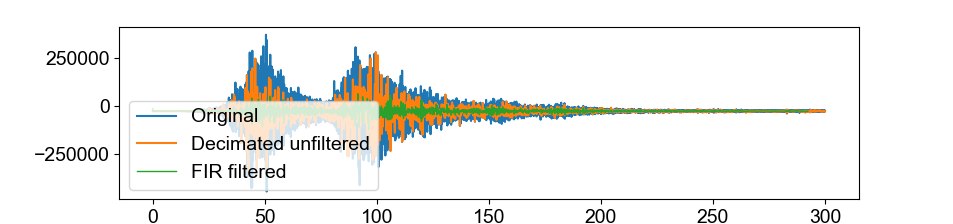

In [20]:
%matplotlib widget

mseed = '20110311_japan_subduction11_miniseeds/20110311054626.KI.J1434.HLZ.mseed'
st = read(mseed)

# mseed2 = 'downsampled_japan_mseeds/downsampled_japan.KI.J1434.HLZ.mseed'
# st2 = read(mseed2)
tr2 = st[0].copy()
factor = int(tr2.stats.sampling_rate/8)
tr2.decimate(factor,no_filter=True)


with urllib.request.urlopen(URL) as response:
    xml = response.read()
fir_filtered = downsample(st,xml)

fig,ax = plt.subplots(1,figsize=[9.54, 2.24])
ax.plot(st[0].times(),st[0].data,label='Original')
ax.plot(tr2.times(),tr2.data,label='Decimated unfiltered')
ax.plot(fir_filtered[0].times(),fir_filtered[0].data,linewidth=1,label='FIR filtered')
ax.legend()
# ax.plot(st2[0].times(),st2[0].data)

In [21]:
tr2.stats.sampling_rate

8.333333333333334

In [22]:
import glob
mseed = glob.glob('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/*J1434*mseed')
print(mseed)
st = read(mseed[1])

['/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1434.HLN.mseed', '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1434.HLZ.mseed', '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/20110311_japan_subduction11_miniseeds/20110311054626.KI.J1434.HLE.mseed']


In [23]:
# First stations
first_stations = ['J0647', 'J0657','J0654','J1434','J0656','J1300','J0653']

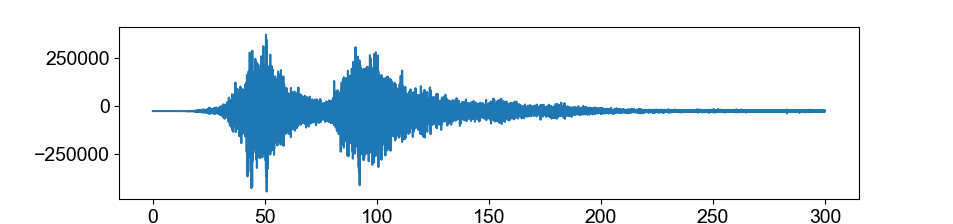

In [24]:
%matplotlib widget
fig,ax = plt.subplots(1,figsize=[9.54, 2.24])
ax.plot(st[0].times(),st[0].data)

In [25]:
plt.gcf().get_size_inches()

array([9.54, 2.24])

In [26]:
test = pd.read_csv('20110311_japan_subduction11.dat')

In [27]:
network = []
station = []
channel = []
lat = []
lon = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']
            network.append(objects[0])
            station.append(objects[1])
            channel.append(objects[3])
            lat.append(float(objects[4]))
            lon.append(float(objects[5]))
        except:
            continue


# Read .dat file
network = []
station = []
location = []
channel = []
lat = []
lon = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']
            if (len(objects)==15) & (objects[0][0]=='K'):
                network.append(objects[0])
                station.append(objects[1])
                channel.append(objects[3])
                lat.append(float(objects[4]))
                lon.append(float(objects[5]))
        except:
            continue

In [28]:
# First stations
first_stations = ['J0647', 'J0657','J0654','J1434','J0656','J1300','J0653']
first_stations = ['J0648','J1434','J0647','J1425','J0657','J1426','J0654','J1322','J1318','J1428']#,'J1300','J0490','J1299']

first_subset_ind = [i for i,name in enumerate(station) if name in first_stations]
first_subset_lat = [lat[i] for i in first_subset_ind]
first_subset_lon = [lon[i] for i in first_subset_ind]

In [29]:
hypo_lat = 38.297
hypo_lon = 142.373

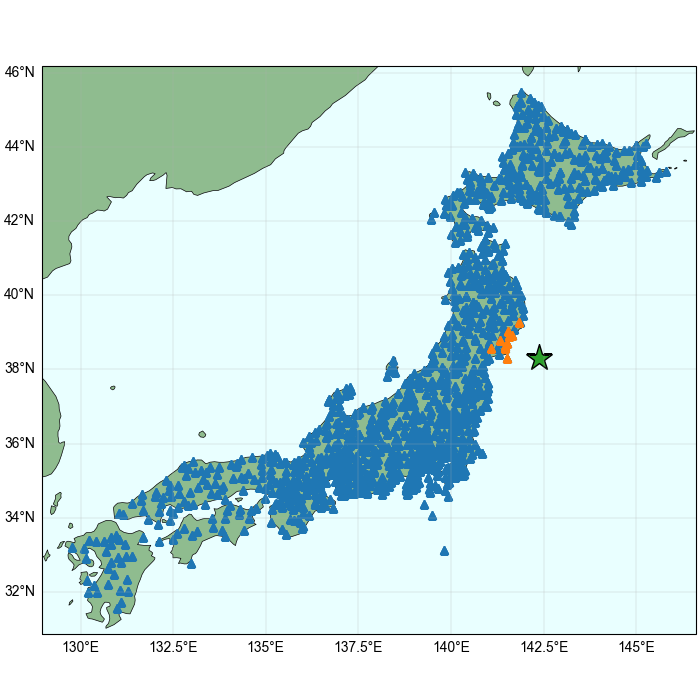

In [30]:
%matplotlib widget

fig = plt.figure(figsize=[7,7],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
# ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.LAND, facecolor='darkseagreen') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

ax.plot(lon,lat,'^')
ax.plot(first_subset_lon,first_subset_lat,'^')
ax.plot(hypo_lon,hypo_lat,'*',markersize=20,markeredgecolor='k')

gl = ax.gridlines(draw_labels=True,linewidth=0.2) 
gl.xlabel_style = {'size':10}
gl.ylabel_style = {'size':10}
gl.top_labels = False
gl.right_labels = False
# gl.bottom_labels=False

## Read the miniseeds and downsample

In [31]:
first_stations = ['J0648','J1434','J0647','J1425','J0657','J1426','J0654','J1322','J1318','J1428']

1 Trace(s) in Stream:
KN.J1034..HLZ | 2011-03-11T05:46:47.000000Z - 2011-03-11T05:51:46.990000Z | 100.0 Hz, 30000 samples
1 Trace(s) in Stream:
KN.J1034..HLZ | 2011-03-11T05:46:47.000000Z - 2011-03-11T05:51:47.000000Z | 8.0 Hz, 2401 samples


Text(0.5, 1.0, 'KN.J1034')

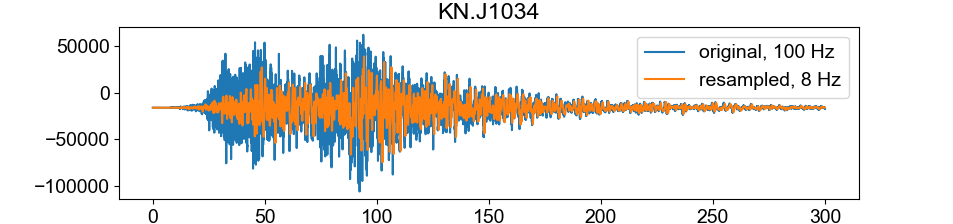

In [32]:
mseed = '/Users/zoekrauss/Downloads/KI.J1434..HLZ.mseed'
mseed = '20110311_japan_subduction11_miniseeds/20110311054626.KN.J1043.HLZ.mseed'
mseed = '20110311_japan_subduction11_miniseeds/20110311054626.KN.J0657.HLZ.mseed'
mseed = '20110311_japan_subduction11_miniseeds/20110311054626.KN.J1034.HLZ.mseed'
st = read(mseed)
print(st)

fig,ax = plt.subplots(1,figsize=[9.54, 2.24])
ax.plot(st[0].times(),st[0].data,label='original, 100 Hz')

st2 = st.copy()
# st2.detrend(type='spline',order=3, dspline=500)
# st2.taper(max_percentage=0.05, type="hann")
# st2[0].data = lowpass(st2[0].data,freq=3.5,df = st2[0].stats.sampling_rate, zerophase = True)
t1 = st2[0].stats.starttime
t2 = st2[0].stats.endtime
st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2[0].data)),pad=True)

st2.resample(8.0,no_filter=False)
st2.trim(t1,t2)
print(st2)

ax.plot(st2[0].times(),st2[0].data,label='resampled, 8 Hz')
# ax.plot(st2[0].times(),st2[0].data,label='demeaned, tapered, resampled')
# st2.decimate(int(np.ceil(100/8)))

ax.legend()

ax.set_title('KN.J1034')

In [33]:
all_miniseeds = glob.glob('20110311_japan_subduction11_miniseeds/*')               

In [45]:
networks = []
stations = []
channels = []
lats = []
lons = []
max_raw_amp = []
median_raw_amp = []
max_ds_amp = []
median_ds_amp = []
write_path = 'all_firfiltered_japan_mseeds'

In [46]:
for i in range(len(all_miniseeds)):
    mseed = all_miniseeds[i]
    st = read(mseed)

    networks.append(st[0].stats.network)
    stations.append(st[0].stats.station)
    channels.append(st[0].stats.channel)

    dat_ind = [j for j,s in enumerate(station) if s==st[0].stats.station][0]
    lats.append(lat[dat_ind])
    lons.append(lon[dat_ind])

    # Get original amplitudes
    max_raw_amp.append(np.max(np.abs(st[0].data)))
    median_raw_amp.append(np.mean(st[0].data))

    # if st[0].stats.station in first_stations:
    # print(st[0].stats.station)
    # Now decimate
    st2 = st.copy()
    t1 = st2[0].stats.starttime
    t2 = st2[0].stats.endtime
    st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2[0].data)),pad=True) # pad ends so we can cut off edge effects

    # FIR filter ala what is set up in Earthscope
    fir_filtered = downsample(st2,xml)

    st2 = fir_filtered
    # factor = int(st2[0].stats.sampling_rate/8)
    # st2.decimate(factor,no_filter=True)
    st2.trim(t1,t2) # cut off edge effects
    # else:
    # st2 = st.copy()

    # Get downsampled amplitudes
    max_ds_amp.append(np.max(np.abs(st2[0].data)))
    median_ds_amp.append(np.mean(st2[0].data))

    # Convert to int 
    tr = st2[0]
    tr.data = tr.data.astype(int)

    # Write to file
    mseed_name = '.'.join(['firfiltered_japan']+mseed.split('.')[1:])
    tr.write(write_path + '/' + mseed_name, format = 'MSEED')

In [47]:
amp_ratio = [max_ds_amp[i]/max_raw_amp[i] for i in range(len(max_ds_amp))]

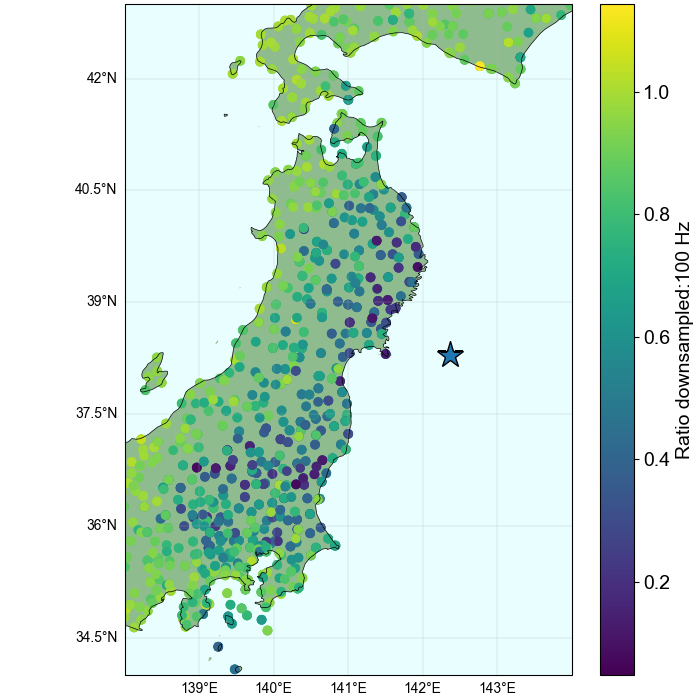

In [48]:
%matplotlib widget

fig = plt.figure(figsize=[7,7],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
# ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.LAND, facecolor='darkseagreen') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

# ax.plot(lon,lat,'^')
# ax.plot(first_subset_lon,first_subset_lat,'^')

c = ax.scatter(lons,lats,c=amp_ratio)

ax.plot(hypo_lon,hypo_lat,'*',markersize=20,markeredgecolor='k')

gl = ax.gridlines(draw_labels=True,linewidth=0.2) 
gl.xlabel_style = {'size':10}
gl.ylabel_style = {'size':10}
gl.top_labels = False
gl.right_labels = False
# gl.bottom_labels=False

ax.set_xlim([138,144])
ax.set_ylim([34,43])

fig.colorbar(c,label='Ratio downsampled:100 Hz')

In [49]:
hypo_dists = [geodesic((lats[i],lons[i]),(hypo_lat,hypo_lon)).km for i in range(len(lats))]

(0.0, 1.2)

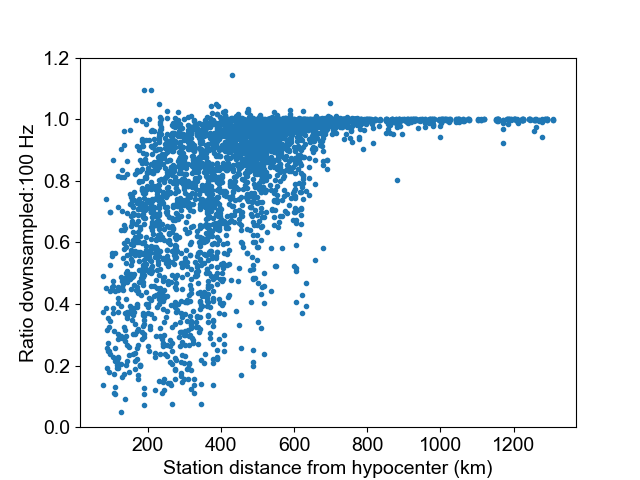

In [50]:
fig,ax = plt.subplots(1)
ax.plot(hypo_dists,amp_ratio,'.')
ax.set_xlabel('Station distance from hypocenter (km)')
ax.set_ylabel('Ratio downsampled:100 Hz')
ax.set_ylim(0,1.2)

## Write .dat file

In [244]:
# Read .dat file
network = []
station = []
location = []
channel = []
latitude = []
longitude = []
elevation = []
samplerate = []
gain = []
units = []
groundmotionclip = []
azimuth = []
dip = []
sensortype = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']
            if (len(objects)==15) & (objects[0][0]=='K'):
                network.append(objects[0])
                station.append(objects[1])
                location.append(objects[2])
                channel.append(objects[3])
                latitude.append(float(objects[4]))
                longitude.append(float(objects[5]))
                elevation.append(float(objects[6]))

                
                # MANUAL SAMPLE RATE
                if objects[1] in first_stations:
                    samplerate.append('8.0')
                else:
                    samplerate.append(objects[7])

                gain.append(objects[8])
                units.append(objects[9])
                groundmotionclip.append(objects[10])
                azimuth.append(objects[11])
                dip.append(objects[12])
                sensortype.append(objects[13])
        except:
            continue

In [245]:
new_dat = pd.DataFrame({'network':network,'station':station,'location':location,'channel':channel,'latitude':latitude,
                       'longitude':longitude,'elevation':elevation,'samplerate':samplerate,'gain':gain,'units':units,'groundmotionclip':groundmotionclip,
                       'azimuth':azimuth,'dip':dip,'sensortype':sensortype})
new_dat

,network,station,location,channel,latitude,longitude,elevation,samplerate,gain,units,groundmotionclip,azimuth,dip,sensortype
0,KI,J1480,--,HLN,36.4663,138.1474,395.0,100.0,1574.18392857,counts/(cm/sec2),4000.00,0,0,UNKNOWN
1,KI,J1656,--,HLE,36.5480,140.0751,105.0,100.0,1574.18392857,counts/(cm/sec2),4000.00,90,0,UNKNOWN
2,KI,J1053,--,HLE,44.0640,144.9935,65.0,100.0,1574.18392857,counts/(cm/sec2),4000.00,90,0,UNKNOWN
3,KI,J1171,--,HLZ,37.2169,140.5703,470.0,100.0,1574.18392857,counts/(cm/sec2),4000.00,0,-90,UNKNOWN
4,KI,J1116,--,HLN,40.4492,141.3374,65.0,100.0,1574.18392857,counts/(cm/sec2),4000.00,0,0,UNKNOWN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3673,KN,J0348,--,HLN,42.3483,141.0319,4.0,100.0,1577.23494898,counts/(cm/sec2),4000.00,0,0,UNKNOWN
3674,KN,J0749,--,HLE,38.2301,139.4864,8.0,100.0,1577.23494898,counts/(cm/sec2),4000.00,90,0,UNKNOWN
3675,KN,J0125,--,HLZ,35.4965,135.7519,3.0,100.0,1577.23494898,counts/(cm/sec2),4000.00,0,-90,UNKNOWN
3676,KN,J0475,--,HLE,37.0427,136.9681,3.0,100.0,1577.23494898,counts/(cm/sec2),4000.00,90,0,UNKNOWN


In [246]:
new_dat.to_csv('first10_downsampled_japan_mseeds.dat', sep = '\t', index = False, header = False)

## Tar up miniseeds

In [247]:
!tar czf first10_downsampled_japan_mseeds.tar.gz first10_downsampled_japan_mseeds
# !scp /Users/zoekrauss/shakealert_8hz/downsampled_mseeds/first10_downsampled_japan_mseeds.tar.gz zkrauss@eew-uw-dev1.ess.washington.edu:/data/eewdata/miniseeds/japan_downsampled




## Make separate dats for downsampled and non-downsampled stations

In [248]:
# FIRST - the NOT downsampled

# Read .dat file
network = []
station = []
location = []
channel = []
latitude = []
longitude = []
elevation = []
samplerate = []
gain = []
units = []
groundmotionclip = []
azimuth = []
dip = []
sensortype = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']

            if (len(objects)==15) & (objects[0][0]=='K'):

                    # Only write if this station wasn't downsampled
                    if objects[1] not in first_stations:
                        network.append(objects[0])
                        station.append(objects[1])
                        location.append(objects[2])
                        channel.append(objects[3])
                        latitude.append(float(objects[4]))
                        longitude.append(float(objects[5]))
                        elevation.append(float(objects[6]))
        
                        samplerate.append(objects[7])
        
                        gain.append(objects[8])
                        units.append(objects[9])
                        groundmotionclip.append(objects[10])
                        azimuth.append(objects[11])
                        dip.append(objects[12])
                        sensortype.append(objects[13])
        except:
            continue

new_dat = pd.DataFrame({'network':network,'station':station,'location':location,'channel':channel,'latitude':latitude,
                       'longitude':longitude,'elevation':elevation,'samplerate':samplerate,'gain':gain,'units':units,'groundmotionclip':groundmotionclip,
                       'azimuth':azimuth,'dip':dip,'sensortype':sensortype})

new_dat.to_csv('first10_downsampled_100hz_japan_mseeds.dat', sep = '\t', index = False, header = False)



In [249]:
# Next - the downsampled stations

# Read .dat file
network = []
station = []
location = []
channel = []
latitude = []
longitude = []
elevation = []
samplerate = []
gain = []
units = []
groundmotionclip = []
azimuth = []
dip = []
sensortype = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']

            if (len(objects)==15) & (objects[0][0]=='K'):

                    # Only write if this station WAS downsampled
                    if objects[1] in first_stations:
                        network.append(objects[0])
                        station.append(objects[1])
                        location.append(objects[2])
                        channel.append(objects[3])
                        latitude.append(float(objects[4]))
                        longitude.append(float(objects[5]))
                        elevation.append(float(objects[6]))

                        # Manually fixing sample rate
                        samplerate.append('8.0')
        
                        gain.append(objects[8])
                        units.append(objects[9])
                        groundmotionclip.append(objects[10])
                        azimuth.append(objects[11])
                        dip.append(objects[12])
                        sensortype.append(objects[13])
        except:
            continue

new_dat = pd.DataFrame({'network':network,'station':station,'location':location,'channel':channel,'latitude':latitude,
                       'longitude':longitude,'elevation':elevation,'samplerate':samplerate,'gain':gain,'units':units,'groundmotionclip':groundmotionclip,
                       'azimuth':azimuth,'dip':dip,'sensortype':sensortype})

new_dat.to_csv('first10_downsampled_8hz_japan_mseeds.dat', sep = '\t', index = False, header = False)